# Stage 0: Data curation for the BD Weapon Dataset (single and multi)

This notebook runs **once, before background removal and training**. It produces a standardized, deduplicated and audited dataset, plus **one fixed set of splits** that every later notebook and all three analyses reuse:

1. **All**: single and multi images together
2. **Single**: only images with one weapon
3. **Multi**: only images with several weapons

Every image gets a `subset` tag (`single` or `multi`). The locked test set and the 5 folds are balanced by **class and subset together**, so the single and multi parts of the test set and of each fold are themselves balanced. Scenario 2 simply uses the single rows of the same split, scenario 3 the multi rows. This keeps the three analyses directly comparable.

**Input:** the dataset, which may be uploaded as **several Kaggle datasets** (here `bd-local-weapon-dataset-1`, `-2`, `-3`). Attach all parts; they are merged automatically. Inside each part, either layout works, and a part may hold all classes or only some of them:

```
BD Weapon Dataset/              (in each part: all classes or only some)
    Churi/
        Churi_single/   Churi_multi/
    Dao/
        Dao_single/     Dao_multi/
    ...
```
Other layouts also work, e.g. `single/Churi/...` or `Churi/single/...`.

Subset folders are recognised by a `single` or `multi` word in the folder name, e.g. `Churi_single`, `Churi_multi`, `single`, `Multiple`. Class folders are recognised by name through `CLASS_ALIASES` (case does not matter, and spelling variants such as Khur/Khor or Sabol/Shabol map to one class). Each file is tagged with the part it came from (`part`).

**Output (`/kaggle/working/stage0`):** `standardized/` images, `metadata/manifest.csv` (image, label, **subset**, split, fold, group), inventory, duplicate pairs, review sheet, camera-per-class table, report, and figures.

**Defaults:** unreadable files are excluded; near-duplicates are removed (one copy kept); a photo filed under two classes is dropped; files named `<name>_left/_up/_down` stay together with `<name>`; every other flag (blur, size, exposure, label suspects) is kept and only listed for review.

## 0. Setup

In [1]:
# Install anything missing (works in Colab, Kaggle and local Jupyter)
import importlib, subprocess, sys

def _ensure(pip_name, import_name):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name, import_name in [("imagehash", "imagehash"), ("opencv-python-headless", "cv2"),
                              ("scikit-learn", "sklearn"), ("pandas", "pandas"),
                              ("matplotlib", "matplotlib"), ("tqdm", "tqdm")]:
    _ensure(pip_name, import_name)

# Optional: HEIC/HEIF support for iPhone photos
# _ensure("pillow-heif", "pillow_heif")

In [2]:
# ============================== CONFIGURATION ==============================
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").is_dir()

# Dataset parts: every attached input whose folder name starts with this is used and merged
DATASET_PREFIX = "bd-local-weapon-dataset"     # matches bd-local-weapon-dataset-1, -2, -3

# Class name used in results -> folder spellings that mean this class (case does not matter)
CLASS_ALIASES = {
    "Churi":  ["churi", "chhuri", "chury"],
    "Dao":    ["dao", "daa", "dau"],
    "Khor":   ["khor", "khur", "khoor"],
    "Kodal":  ["kodal", "kodaal"],
    "Kural":  ["kural", "kurral", "kurol"],
    "Shabol": ["shabol", "sabol", "shobol", "sabal", "shabal"],
}
SINGLE_PREFIX = "single"   # subset folder names starting with this -> single
MULTI_PREFIX  = "multi"    # subset folder names starting with this -> multi ("multi", "multiple", ...)

if ON_KAGGLE:
    DATA_SEARCH_ROOT = Path("/kaggle/input")       # the dataset parts are found automatically
    OUT_ROOT         = Path("/kaggle/working/stage0") # the only writable location on Kaggle
    # found automatically if you attach your edited sheet as a dataset whose name contains "review"
    REVIEW_INPUT     = next((p for p in Path("/kaggle/input").rglob("review_decisions.csv")
                             if "review" in str(p.parent).lower() and "stage0" not in str(p)), None)
else:
    DATA_SEARCH_ROOT = Path(r"H:\BD Weapon Dataset")
    OUT_ROOT         = Path(r"H:\BD Weapon Stage0")   # keep outputs outside the raw dataset folder
    REVIEW_INPUT     = None  # locally the sheet is edited in place in OUT_ROOT/metadata
print("REVIEW_INPUT:", REVIEW_INPUT)
SEED      = 42

# --- Standardization ---
MAX_SIDE      = 1600  # downscale when the long side is larger (keeps disk use sane); None keeps full resolution
FORCE_REBUILD = False # True re-reads every raw file even if a cached result exists

# --- Duplicates ---
REMOVE_DUPLICATES = True   # keep one copy per near-duplicate cluster
KEEP_NAMED_COPIES = True   # <name>_left / _up / _down files stay with <name> and are not removed as duplicates of it
REUSE_PREVIOUS    = True   # Kaggle: if a previous version of this notebook is attached, reuse its standardized images

# --- Duplicate detection (Hamming distance between 64-bit perceptual hashes) ---
DUP_PHASH_THR  = 6    # pHash distance for a near-duplicate
DUP_DHASH_THR  = 10   # dHash distance must also be within this (reduces false positives)
CHECK_MIRRORED = True # also catch horizontally flipped copies
DUP_VERIFY_GRAY_CORR = 0.90  # candidate confirmed only if 64x64 grayscale correlation is at least this
DUP_VERIFY_EDGE_CORR = 0.80  # ... and edge-map correlation is at least this

# --- Quality flags ---
QUALITY_SIDE     = 512   # metrics are computed after resizing the long side to this, so they are comparable
BLUR_MAD_K       = 3.0   # blurry if log10(Laplacian variance) < median - k * MAD (robust, dataset-relative)
MIN_SHORT_SIDE   = 128   # flag images whose original short side is below this
UPSCALE_CANDIDATE_SIDE = 256  # marked for possible super-resolution in P9 (information only)
DARK_MEAN, BRIGHT_MEAN = 40, 215  # mean luminance limits (0-255)
CLIP_FRAC        = 0.25  # flag if more than this fraction of pixels is pure black or pure white
LOW_CONTRAST_STD = 20    # flag if luminance standard deviation is below this

# --- Label audit with pretrained embeddings (needs torch + torchvision; skipped if missing) ---
USE_EMBEDDINGS    = True
KNN_K             = 5
KNN_DISAGREE_FRAC = 0.8  # flag if at least this fraction of the k nearest neighbours has another label
OUTLIER_MAD_K     = 3.0  # flag if distance to own class centroid > median + k * MAD

# --- Splits ---
TEST_FRACTION   = 0.15   # held-out test set, touched only for the final report
N_FOLDS         = 5      # stratified group folds on the remaining data
GROUP_PHASH_THR = 12     # looser than DUP_PHASH_THR: images this similar are forced into the same split
MAX_GROUP_FRAC  = 0.02   # if any group exceeds this share of the data, the threshold is tightened automatically
GROUPS_CSV      = None   # optional CSV (columns: rel_path, group_id) that ties photos of the same object
if ON_KAGGLE and GROUPS_CSV is None:   # used if a groups.csv is attached
    GROUPS_CSV = next((p for p in sorted(Path("/kaggle/input").rglob("groups.csv"))
                       if "stage0" not in p.parts and p.read_text().startswith("rel_path,group_id")), None)
print("GROUPS_CSV:", GROUPS_CSV)

REVIEW_INPUT: None
GROUPS_CSV: None


In [3]:
import io, json, hashlib, shutil, platform, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import imagehash
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from PIL import Image, ImageOps, ImageCms, __version__ as PIL_VERSION
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

Image.MAX_IMAGE_PIXELS = 250_000_000   # allow large phone photos, still guard against decompression bombs
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 160, "display.max_columns", 30)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff", ".gif", ".heic", ".heif", ".jfif"}
STD_DIR, META, FIG = OUT_ROOT / "standardized", OUT_ROOT / "metadata", OUT_ROOT / "figures"
for d in (STD_DIR, META, FIG):
    d.mkdir(parents=True, exist_ok=True)

# Reuse standardized images and caches from an attached previous run (same dataset version)
if ON_KAGGLE and REUSE_PREVIOUS and not FORCE_REBUILD:
    prev = next((p.parent.parent for p in Path("/kaggle/input").rglob("inventory_cache.pkl")
                 if p.parent.name == "metadata" and p.parent.parent.name == "stage0"), None)
    if prev is not None and not (META / "inventory_cache.pkl").exists():
        shutil.copytree(prev / "standardized", STD_DIR, dirs_exist_ok=True)
        for f in ["inventory_cache.pkl", "embeddings_resnet50.npz"]:
            if (prev / "metadata" / f).exists():
                shutil.copy2(prev / "metadata" / f, META / f)
        print(f"Reused {sum(1 for _ in STD_DIR.iterdir())} standardized images and caches from {prev}")
    else:
        print("No previous Stage 0 output attached: processing all images from scratch.")
def _has_images(folder, limit=200):
    for i, f in enumerate(folder.rglob("*")):
        if f.is_file() and f.suffix.lower() in IMG_EXTS:
            return True
        if i > limit:
            break
    return False

import os, re
def _tokens(name):
    return [t for t in re.split(r"[_\-\s.]+", name.strip().lower()) if t]

def _subset_of(name):
    # "single", "Churi_single", "Dao-Multi", "multiple", "Single weapon" ...
    toks = _tokens(name)
    if any(t.startswith(SINGLE_PREFIX) for t in toks):
        return "single"
    if any(t.startswith(MULTI_PREFIX) for t in toks):
        return "multi"
    return None

def _class_of(name):
    # "Churi", "churi", "Churi_single", "Khur_multi" ...
    n = name.strip().lower()
    if n in ALIAS:
        return ALIAS[n]
    hits = {ALIAS[t] for t in _tokens(name) if t in ALIAS}
    return hits.pop() if len(hits) == 1 else None

ALIAS = {a.lower(): c for c, al in CLASS_ALIASES.items() for a in [c] + al}
CLASSES = sorted(CLASS_ALIASES)

assert DATA_SEARCH_ROOT.is_dir(), f"Folder not found: {DATA_SEARCH_ROOT}"
PART_ROOTS = []
for dirpath, dirnames, _ in os.walk(DATA_SEARCH_ROOT, followlinks=True):
    d = Path(dirpath)
    if len(d.relative_to(DATA_SEARCH_ROOT).parts) > 4:
        dirnames[:] = []; continue
    hits = [x for x in dirnames if x.lower().startswith(DATASET_PREFIX.lower())]
    PART_ROOTS += [d / x for x in hits]
    dirnames[:] = [x for x in dirnames if x not in hits and x not in ("stage0", "bg_removed")]
PART_ROOTS = sorted(set(PART_ROOTS))
if not PART_ROOTS:
    seen = sorted({p.name for p in DATA_SEARCH_ROOT.glob("*/*")} | {p.name for p in DATA_SEARCH_ROOT.glob("*")})[:40]
    raise FileNotFoundError(f"No input folder starting with '{DATASET_PREFIX}' under {DATA_SEARCH_ROOT}. "
                            f"Attach the dataset parts (Add Input). Seen: {seen}")
DATA_ROOT = Path(os.path.commonpath([str(p) for p in PART_ROOTS])) if len(PART_ROOTS) > 1 else PART_ROOTS[0].parent
LAYOUT = "merged parts"
print("Dataset parts found:")
for p in PART_ROOTS:
    print("  ", p)
print(f"Classes ({len(CLASSES)}): {CLASSES}")
print("DATA_ROOT:", DATA_ROOT)
print("OUT_ROOT :", OUT_ROOT)

# Bring in an edited review sheet (Kaggle: from an attached dataset)
if REVIEW_INPUT is not None:
    assert Path(REVIEW_INPUT).is_file(), f"REVIEW_INPUT not found: {REVIEW_INPUT}"
    shutil.copy(REVIEW_INPUT, META / "review_decisions.csv")
    print("Review decisions loaded from", REVIEW_INPUT)

No previous Stage 0 output attached: processing all images from scratch.
Dataset parts found:
   /kaggle/input/datasets/arnicasarker/bd-local-weapon-dataset-1
   /kaggle/input/datasets/arnicasarker/bd-local-weapon-dataset-2
   /kaggle/input/datasets/arnicasarker/bd-local-weapon-dataset-3
Classes (6): ['Churi', 'Dao', 'Khor', 'Kodal', 'Kural', 'Shabol']
DATA_ROOT: /kaggle/input/datasets/arnicasarker
OUT_ROOT : /kaggle/working/stage0


### Helper functions

In [4]:
SRGB_PROFILE = ImageCms.createProfile("sRGB")

def std_path(image_id):
    return STD_DIR / f"{image_id}.png"

def _to_uint8(im):
    # 16-bit / 32-bit / float grayscale -> 8-bit
    arr = np.asarray(im, dtype=np.float64)
    hi = 65535.0 if arr.max() > 255 else 255.0
    return np.clip(arr / hi * 255.0 + 0.5, 0, 255).astype(np.uint8)

def standardize(src):
    # Open, fully decode, fix orientation, convert to 8-bit sRGB RGB, flatten alpha on white, downscale.
    meta = {}
    with Image.open(src) as im:
        meta["orig_format"] = im.format
        meta["orig_mode"] = im.mode
        meta["n_frames"] = getattr(im, "n_frames", 1)
        im.seek(0)                        # multi-frame GIF/TIFF: use the first frame
        im.load()                         # full decode: truncated or corrupt files fail here
        exif = im.getexif()
        meta["exif_orientation"] = int(exif.get(0x0112, 1) or 1)
        meta["camera"] = " ".join(str(exif.get(t, "")).strip("\x00 ") for t in (0x010F, 0x0110)).strip()
        icc = im.info.get("icc_profile")
        im = ImageOps.exif_transpose(im)  # physically rotate, drop the orientation tag
        meta["orig_w"], meta["orig_h"] = im.size

        if im.mode in ("I;16", "I;16B", "I;16L", "I;16N", "I", "F"):
            im = Image.fromarray(_to_uint8(im))
        elif im.mode == "1":
            im = im.convert("L")

        alpha = None
        if im.mode == "P" and "transparency" not in im.info:
            im = im.convert("RGB")
        elif im.mode in ("P", "PA", "LA", "La", "RGBA", "RGBa"):
            im = im.convert("RGBA")
            alpha = im.getchannel("A")
            im = im.convert("RGB")

        meta["icc_converted"] = False
        if icc and im.mode in ("RGB", "CMYK", "L"):
            try:
                src_prof = ImageCms.ImageCmsProfile(io.BytesIO(icc))
                im = ImageCms.profileToProfile(im, src_prof, SRGB_PROFILE, outputMode="RGB")
                meta["icc_converted"] = True
            except Exception:
                pass                      # unusable profile: fall back to a plain conversion
        if im.mode != "RGB":
            im = im.convert("RGB")        # CMYK without profile, L, YCbCr, ...

        meta["had_alpha"] = alpha is not None and alpha.getextrema()[0] < 255
        if alpha is not None:
            bg = Image.new("RGB", im.size, (255, 255, 255))
            bg.paste(im, mask=alpha)
            im = bg

        meta["downscaled"] = False
        if MAX_SIDE and max(im.size) > MAX_SIDE:
            s = MAX_SIDE / max(im.size)
            im = im.resize((max(1, round(im.width * s)), max(1, round(im.height * s))),
                           Image.Resampling.LANCZOS, reducing_gap=3.0)
            meta["downscaled"] = True
        im = im.copy()
    return im, meta

def image_metrics(im):
    rgb = np.asarray(im)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    h, w = gray.shape
    s = QUALITY_SIDE / max(h, w)
    g = cv2.resize(gray, (max(1, round(w * s)), max(1, round(h * s))),
                   interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    mirrored = ImageOps.mirror(im)
    return {
        "lap_var": float(cv2.Laplacian(g, cv2.CV_64F).var()),
        "mean_lum": float(g.mean()),
        "std_lum": float(g.std()),
        "frac_black": float((g <= 5).mean()),
        "frac_white": float((g >= 250).mean()),
        "mean_sat": float(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1].mean()),
        "phash": str(imagehash.phash(im)),
        "dhash": str(imagehash.dhash(im)),
        "phash_mirror": str(imagehash.phash(mirrored)),
        "dhash_mirror": str(imagehash.dhash(mirrored)),
        "pixel_md5": hashlib.md5(rgb.tobytes() + str(rgb.shape).encode()).hexdigest(),
    }

# ---- vectorised Hamming distance between 64-bit hashes ----
_POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def hashes_to_u64(hex_list):
    return np.array([int(h, 16) for h in hex_list], dtype=np.uint64)

def hamming(a, b, chunk=512):
    out = np.empty((len(a), len(b)), dtype=np.uint8)
    for s in range(0, len(a), chunk):
        x = np.ascontiguousarray(a[s:s + chunk, None] ^ b[None, :])
        out[s:s + chunk] = _POPCOUNT[x.view(np.uint8)].reshape(x.shape + (8,)).sum(-1)
    return out

def connected_components(n, edges):
    parent = np.arange(n)
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for a, b in edges:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    roots = np.array([find(i) for i in range(n)])
    return np.unique(roots, return_inverse=True)[1]

def contact_sheet(ids, titles, out_stem, ncols=6, per_page=36, thumb=220, suptitle="", show_first=True):
    # Save thumbnail grids (several pages if needed). Returns the list of saved files.
    ids, titles = list(ids), list(titles)
    saved = []
    for p in range(0, len(ids), per_page):
        chunk_ids, chunk_titles = ids[p:p + per_page], titles[p:p + per_page]
        nrows = int(np.ceil(len(chunk_ids) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.6, nrows * 2.9), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        for ax, iid, t in zip(axes.ravel(), chunk_ids, chunk_titles):
            with Image.open(std_path(iid)) as im:
                im.thumbnail((thumb, thumb))
                ax.imshow(np.asarray(im))
            ax.set_title(t, fontsize=7)
        page = p // per_page + 1
        fig.suptitle(f"{suptitle}  (page {page})", fontsize=10)
        fig.tight_layout()
        out = FIG / f"{out_stem}_p{page:02d}.png"
        fig.savefig(out, dpi=110)
        saved.append(out)
        if show_first and page == 1:
            plt.show()
        plt.close(fig)
    return saved

## 1. Inventory

Lists every file under each class folder and assigns a stable `image_id` (a hash of the relative path), so IDs stay the same across reruns.

In [5]:
rows, skipped, unknown_dirs = [], [], Counter()
for part in PART_ROOTS:
    for f in sorted(part.rglob("*")):
        if not f.is_file() or f.name.startswith(".") or "__MACOSX" in f.parts:
            continue
        dirs = f.relative_to(part).parts[:-1]                 # folder names only (not the file name)
        subsets = [_subset_of(x) for x in dirs if _subset_of(x)]
        classes = [_class_of(x) for x in dirs if _class_of(x)]
        if not subsets or len(set(classes)) != 1:
            skipped.append(f.relative_to(DATA_SEARCH_ROOT).as_posix())
            unknown_dirs.update(x for x in dirs if not _subset_of(x) and not _class_of(x))
            continue
        rel = f.relative_to(DATA_ROOT).as_posix()
        st = f.stat()
        rows.append({"image_id": hashlib.sha1(rel.encode()).hexdigest()[:12], "rel_path": rel,
                     "orig_label": classes[0], "subset": subsets[0], "part": part.name,
                     "ext": f.suffix.lower(), "file_bytes": st.st_size, "mtime_ns": st.st_mtime_ns})
if skipped:
    warnings.warn(f"{len(skipped)} file(s) not inside a recognised <class> and <single|multi> folder are ignored, "
                  f"e.g. {skipped[:5]}. Unrecognised folder names: {unknown_dirs.most_common(10)}. "
                  "If one of these is a class, add its spelling to CLASS_ALIASES.")
inv = pd.DataFrame(rows)
assert len(inv), "No files found."
assert inv.image_id.is_unique, "image_id collision; rename the offending files."

print(f"Classes: {CLASSES}")
print(f"Files found: {len(inv)}")
display(pd.crosstab(inv.orig_label, inv.subset, margins=True, margins_name="total").rename_axis(index="class", columns="files"))
print("Files per dataset part:")
display(pd.crosstab([inv.part], [inv.orig_label, inv.subset], margins=True, margins_name="total"))
missing_cls = [c for c in CLASSES if c not in set(inv.orig_label)]
if missing_cls:
    warnings.warn(f"No files found for class(es) {missing_cls}: they are dropped. Check the folder spelling / CLASS_ALIASES.")
    CLASSES = [c for c in CLASSES if c not in missing_cls]
display(inv.ext.value_counts().rename("count").to_frame().T)

Classes: ['Churi', 'Dao', 'Khor', 'Kodal', 'Kural', 'Shabol']
Files found: 3075


files,multi,single,total
class,,,
Churi,223,307,530
Dao,224,309,533
Khor,182,354,536
Kodal,189,293,482
Kural,180,306,486
Shabol,228,280,508
total,1226,1849,3075


Files per dataset part:


orig_label                Churi          Dao         Khor        Kodal        Kural        Shabol        total
subset                    multi single multi single multi single multi single multi single  multi single      
part                                                                                                          
bd-local-weapon-dataset-1   223    307   224    309     0      0     0      0     0      0      0      0  1063
bd-local-weapon-dataset-2     0      0     0      0     0      0   189    293   180    306      0      0   968
bd-local-weapon-dataset-3     0      0     0      0   182    354     0      0     0      0    228    280  1044
total                       223    307   224    309   182    354   189    293   180    306    228    280  3075

ext,.jpg,.jpeg,.png
count,3022,51,2


## 2. Integrity check and standardization

For every file: full decode (catches corrupt and truncated files), EXIF orientation fix, conversion to 8-bit sRGB RGB (CMYK, palette, 16-bit, grayscale and ICC-tagged images), alpha flattened on white, optional downscale, saved as lossless PNG with no metadata. Quality metrics and perceptual hashes are computed on the same image.

Results are cached, so reruns only process new or changed files.

In [6]:
CACHE = META / "inventory_cache.pkl"
cache = pd.read_pickle(CACHE).set_index("image_id") if CACHE.exists() and not FORCE_REBUILD else None

records = []
for r in tqdm(inv.itertuples(index=False), total=len(inv), desc="standardizing"):
    rec = r._asdict()
    if cache is not None and r.image_id in cache.index:
        c = cache.loc[r.image_id]
        if (c.file_bytes == r.file_bytes and c.max_side == (MAX_SIDE or 0)
                and (c.status != "ok" or std_path(r.image_id).exists())):
            rec.update({k: c[k] for k in c.index if k not in rec})
            records.append(rec)
            continue
    rec["max_side"] = MAX_SIDE or 0
    if r.ext not in IMG_EXTS:
        rec.update(status="not_image", error=f"extension {r.ext}")
        records.append(rec)
        continue
    try:
        im, meta = standardize(DATA_ROOT / r.rel_path)
        im.save(std_path(r.image_id), format="PNG")
        rec.update(meta)
        rec.update(image_metrics(im))
        rec.update(status="ok", error="", width=im.width, height=im.height)
    except Exception as e:
        rec.update(status="unreadable", error=f"{type(e).__name__}: {e}"[:300])
    records.append(rec)

inv = pd.DataFrame(records)
inv.to_pickle(CACHE)

print(inv.status.value_counts().to_string())
bad = inv[inv.status != "ok"]
if len(bad):
    print("\nExcluded files:")
    display(bad[["rel_path", "status", "error"]])
ok = inv[inv.status == "ok"].reset_index(drop=True)
print(f"\nReadable images: {len(ok)}")
print(f"EXIF-rotated: {(ok.exif_orientation != 1).sum()} | ICC converted: {ok.icc_converted.sum()} | "
      f"had transparency: {ok.had_alpha.sum()} | downscaled: {ok.downscaled.sum()} | "
      f"non-RGB source modes: {(~ok.orig_mode.isin(['RGB'])).sum()}")

standardizing:   0%|          | 0/3075 [00:00<?, ?it/s]

status
ok    3075

Readable images: 3075
EXIF-rotated: 818 | ICC converted: 1244 | had transparency: 0 | downscaled: 2428 | non-RGB source modes: 0


## 3. Quality metrics and flags

Blur uses the variance of the Laplacian on a fixed-size grayscale copy. The threshold is set from the dataset's own distribution (median minus k times the MAD of the log value), not a fixed number, because acceptable sharpness depends on the capture setup. Flags go to manual review; nothing is removed automatically here.

Blur threshold: log10(LapVar) < 1.04  (LapVar < 10.9)


,blurry,small,dark,bright,clipped,low_contrast
flagged,0,0,68,0,30,19


Upscale candidates for P9 (short side < 256px): 0


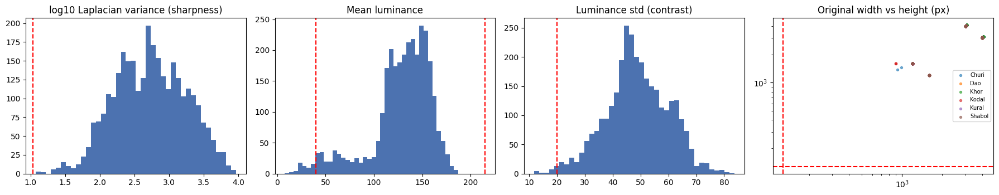

,orig_w,orig_h,lap_var,mean_lum,std_lum,mean_sat
orig_label,,,,,,
Churi,3072.0,4032.0,279.4,108.1,46.1,58.8
Dao,3024.0,4000.0,299.8,144.5,47.2,56.3
Khor,3024.0,4032.0,200.9,114.7,44.9,87.5
Kodal,1204.0,1600.0,994.5,134.3,48.1,39.4
Kural,3000.0,4000.0,1445.9,148.6,52.9,43.9
Shabol,3000.0,4000.0,1286.6,139.8,53.7,45.4


In [7]:
log_lap = np.log10(ok.lap_var + 1e-6)
med = log_lap.median()
mad = 1.4826 * (log_lap - med).abs().median()
BLUR_THR = med - BLUR_MAD_K * mad

ok["short_side"] = ok[["orig_w", "orig_h"]].min(axis=1)
ok["upscale_candidate"] = ok.short_side < UPSCALE_CANDIDATE_SIDE

flag_rules = {
    "blurry":       log_lap < BLUR_THR,
    "small":        ok.short_side < MIN_SHORT_SIDE,
    "dark":         ok.mean_lum < DARK_MEAN,
    "bright":       ok.mean_lum > BRIGHT_MEAN,
    "clipped":      (ok.frac_black > CLIP_FRAC) | (ok.frac_white > CLIP_FRAC),
    "low_contrast": ok.std_lum < LOW_CONTRAST_STD,
}
flags = {iid: [] for iid in ok.image_id}
for name, mask in flag_rules.items():
    for iid in ok.image_id[mask.to_numpy()]:
        flags[iid].append(name)

print(f"Blur threshold: log10(LapVar) < {BLUR_THR:.2f}  (LapVar < {10**BLUR_THR:.1f})")
display(pd.DataFrame({k: [int(v.sum())] for k, v in flag_rules.items()}, index=["flagged"]))
print(f"Upscale candidates for P9 (short side < {UPSCALE_CANDIDATE_SIDE}px): {ok.upscale_candidate.sum()}")

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
axes[0].hist(log_lap, bins=40, color="#4C72B0"); axes[0].axvline(BLUR_THR, color="r", ls="--")
axes[0].set_title("log10 Laplacian variance (sharpness)")
axes[1].hist(ok.mean_lum, bins=40, color="#4C72B0")
for v in (DARK_MEAN, BRIGHT_MEAN): axes[1].axvline(v, color="r", ls="--")
axes[1].set_title("Mean luminance")
axes[2].hist(ok.std_lum, bins=40, color="#4C72B0"); axes[2].axvline(LOW_CONTRAST_STD, color="r", ls="--")
axes[2].set_title("Luminance std (contrast)")
for cls in CLASSES:
    m = ok.orig_label == cls
    axes[3].scatter(ok.orig_w[m], ok.orig_h[m], s=8, label=cls, alpha=0.6)
axes[3].axvline(MIN_SHORT_SIDE, color="r", ls="--"); axes[3].axhline(MIN_SHORT_SIDE, color="r", ls="--")
axes[3].set_xscale("log"); axes[3].set_yscale("log"); axes[3].legend(fontsize=7)
axes[3].set_title("Original width vs height (px)")
fig.tight_layout(); fig.savefig(FIG / "quality_distributions.png", dpi=120); plt.show()

# Per-class quality summary (large class differences here can become shortcuts for the model)
display(ok.groupby("orig_label")[["orig_w", "orig_h", "lap_var", "mean_lum", "std_lum", "mean_sat"]].median().round(1))

### 3b. Source-bias check

If some classes were collected differently from others (for example some classes downloaded from the web and others photographed with a phone), a model can separate classes by **image source** (resolution, file format, camera metadata, compression) instead of by the weapon. That inflates accuracy and does not generalise.

This cell measures how strongly each source attribute is associated with the class label, using Cramer's V (0 = independent, 1 = attribute fully determines the class). Values above about 0.5 deserve attention: collect more images from the under-represented source, or at least report the imbalance and check Grad-CAM maps later.

In [8]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    if min(t.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(t, correction=False)[0]
    return float(np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1))))

src = pd.DataFrame({
    "label": ok.orig_label,
    "file_format": ok.orig_format.fillna("unknown"),
    "resolution": pd.cut(ok.orig_w * ok.orig_h / 1e6, [0, 0.3, 1, 4, 1e9],
                         labels=["<0.3 MP", "0.3-1 MP", "1-4 MP", ">4 MP"]).astype(str),
    "camera_exif": np.where(ok.camera.fillna("").str.len() > 0, "has camera EXIF", "no camera EXIF"),
    "aspect": pd.cut(ok.orig_w / ok.orig_h, [0, 0.9, 1.1, 99], labels=["portrait", "square", "landscape"]).astype(str),
})
bias = pd.Series({c: cramers_v(src.label, src[c]) for c in ["file_format", "resolution", "camera_exif", "aspect"]},
                 name="Cramer's V").round(3)
display(bias.to_frame().T)
for c in ["file_format", "resolution", "camera_exif"]:
    display((pd.crosstab(src.label, src[c], normalize="index") * 100).round(0).astype(int)
            .rename_axis(columns=f"{c} (% of class)"))
high = bias[bias > 0.5]
if len(high):
    warnings.warn(f"Strong class/source association: {dict(high)}. The model may learn the source, not the weapon.")
top_cams = ok.camera.replace("", np.nan).dropna().value_counts().head(10)
if len(top_cams):
    print("Most common cameras:"); print(top_cams.to_string())

# Devices per class and subset (top 6 cameras; the rest grouped). Saved for the paper.
cam = ok.camera.fillna("").str.strip().replace("", "no camera info")
top6 = cam.value_counts().head(6).index
cam_tab = pd.crosstab([ok.orig_label.rename("class"), ok.subset], cam.where(cam.isin(top6), "other cameras"),
                      margins=True, margins_name="total")
print("\nImages per device, by class and subset (all readable images):")
display(cam_tab)
cam_tab.to_csv(META / "camera_by_class_subset.csv")

,file_format,resolution,camera_exif,aspect
Cramer's V,0.198,0.52,0.52,0.217


file_format (% of class),JPEG,MPO
label,,
Churi,96,4
Dao,93,7
Khor,100,0
Kodal,100,0
Kural,100,0
Shabol,100,0


resolution (% of class),1-4 MP,>4 MP
label,,
Churi,0,100
Dao,8,92
Khor,0,100
Kodal,60,40
Kural,34,66
Shabol,29,71


camera_exif (% of class),has camera EXIF,no camera EXIF
label,,
Churi,100,0
Dao,92,8
Khor,100,0
Kodal,40,60
Kural,66,34
Shabol,71,29


Most common cameras:
camera
Apple iPhone 14            1242
Xiaomi REDMI Note 15 5G     647
samsung Galaxy M14          539

Images per device, by class and subset (all readable images):


/tmp/ipykernel_16/3966606630.py:26: UserWarning: Strong class/source association: {'resolution': np.float64(0.52), 'camera_exif': np.float64(0.52)}. The model may learn the source, not the weapon.
  warnings.warn(f"Strong class/source association: {dict(high)}. The model may learn the source, not the weapon.")


camera         Apple iPhone 14  Xiaomi REDMI Note 15 5G  no camera info  samsung Galaxy M14  total
class  subset                                                                                     
Churi  multi               109                        0               0                 114    223
       single              104                        0               2                 201    307
Dao    multi               137                       80               7                   0    224
       single              131                      141              37                   0    309
Khor   multi               182                        0               0                   0    182
       single              130                        0               0                 224    354
Kodal  multi                31                        0             158                   0    189
       single               50                      114             129                   0    293
Kural  multi                22                      158               0                   0    180
       single              141                        0             165                   0    306
Shabol multi                80                        0             148                   0    228
       single              125                      154               1                   0    280
total                     1242                      647             647                 539   3075

## 4. Duplicate and near-duplicate detection

Two-step detection:

1. **Candidates:** pHash and dHash distances both small (also checked against the mirrored image), or identical decoded pixels.
2. **Verification:** hashes alone give false positives on images with similar plain or smooth backgrounds, so each candidate pair is confirmed on 64x64 grayscale thumbnails: intensity correlation >= `DUP_VERIFY_GRAY_CORR` **and** edge-map correlation >= `DUP_VERIFY_EDGE_CORR` (best of direct and mirrored). Edited copies of one photo (resized, recompressed, brightened, mildly blurred) pass; different objects on similar backgrounds fail.

Confirmed pairs are clustered by transitive linking. Rejected candidates are still recorded and are still used for leakage-safe grouping in step 8.

- Same-class clusters: all copies are kept. Detection is used only to keep copies in the same split.
- Cross-class clusters are the same photo filed under two labels; they are flagged `label_conflict` (default `keep`).

Hash candidates: 590 | confirmed duplicates: 155 | rejected by pixel check: 435
Near-duplicate pairs: 155 (0 cross-class)
Clusters with >1 image: 61 covering 186 images -> 125 redundant copies
Images in cross-class (label conflict) clusters: 0


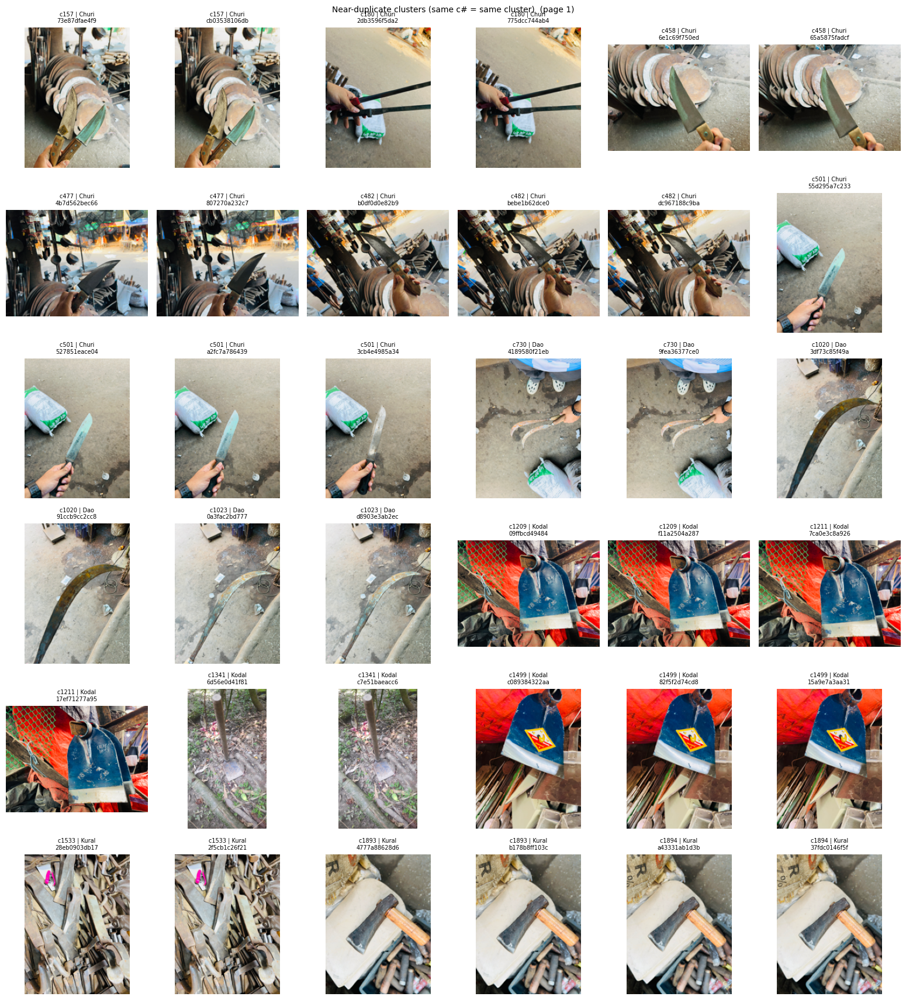

In [9]:
n = len(ok)
P, D = hashes_to_u64(ok.phash), hashes_to_u64(ok.dhash)
dp, dd = hamming(P, P), hamming(D, D)
cand = (dp <= DUP_PHASH_THR) & (dd <= DUP_DHASH_THR)
phash_min = dp.copy()
dpm = np.full_like(dp, 64)
if CHECK_MIRRORED:
    Pm, Dm = hashes_to_u64(ok.phash_mirror), hashes_to_u64(ok.dhash_mirror)
    dpm = hamming(P, Pm); dpm = np.minimum(dpm, dpm.T)
    ddm = hamming(D, Dm); ddm = np.minimum(ddm, ddm.T)
    cand |= (dpm <= DUP_PHASH_THR) & (ddm <= DUP_DHASH_THR)
    phash_min = np.minimum(dp, dpm)
md5 = pd.factorize(ok.pixel_md5)[0]          # integer codes: identical decoded pixels share a code
cand |= md5[:, None] == md5[None, :]
np.fill_diagonal(cand, False)

# ---- pixel-level verification of candidate pairs ----
_thumbs = {}
def _thumb(iid):
    if iid not in _thumbs:
        with Image.open(std_path(iid)) as im:
            g = np.asarray(im.convert("L").resize((64, 64), Image.Resampling.BOX), dtype=np.float64)
        e = np.hypot(cv2.Sobel(g, cv2.CV_64F, 1, 0), cv2.Sobel(g, cv2.CV_64F, 0, 1))
        _thumbs[iid] = (g, e)
    return _thumbs[iid]

def _corr(a, b):
    a = (a - a.mean()) / (a.std() + 1e-6); b = (b - b.mean()) / (b.std() + 1e-6)
    return float((a * b).mean())

def verify_pair(ia, ib):
    (ga, ea), (gb, eb) = _thumb(ia), _thumb(ib)
    best = (-1.0, -1.0)
    for flip in ([False, True] if CHECK_MIRRORED else [False]):
        g2 = gb[:, ::-1] if flip else gb
        e2 = eb[:, ::-1] if flip else eb
        gc = _corr(ga, g2)
        if gc > best[0]:
            best = (gc, _corr(ea, e2))
    return best

ids_np = ok.image_id.to_numpy()
ci, cj = np.nonzero(np.triu(cand, 1))
scores = [verify_pair(ids_np[a], ids_np[b]) for a, b in zip(ci, cj)]
gray_c = np.array([s[0] for s in scores]); edge_c = np.array([s[1] for s in scores])
identical = md5[ci] == md5[cj]
confirmed = identical | ((gray_c >= DUP_VERIFY_GRAY_CORR) & (edge_c >= DUP_VERIFY_EDGE_CORR))

near = np.zeros_like(cand)
near[ci[confirmed], cj[confirmed]] = True
near[cj[confirmed], ci[confirmed]] = True

labels0 = ok.orig_label.to_numpy()
cand_pairs = pd.DataFrame({
    "id_a": ids_np[ci], "id_b": ids_np[cj], "label_a": labels0[ci], "label_b": labels0[cj],
    "phash_dist": dp[ci, cj], "dhash_dist": dd[ci, cj], "phash_dist_mirrored": dpm[ci, cj],
    "gray_corr": gray_c.round(4), "edge_corr": edge_c.round(4),
    "identical_pixels": identical, "is_duplicate": confirmed,
})
cand_pairs["same_label"] = cand_pairs.label_a == cand_pairs.label_b
cand_pairs.to_csv(META / "duplicate_pairs.csv", index=False)
dup_pairs = cand_pairs[cand_pairs.is_duplicate]
ii, jj = ci[confirmed], cj[confirmed]
print(f"Hash candidates: {len(cand_pairs)} | confirmed duplicates: {len(dup_pairs)} | "
      f"rejected by pixel check: {(~confirmed).sum()}")

ok["dup_cluster"] = connected_components(n, zip(ii, jj))
sizes = ok.dup_cluster.map(ok.dup_cluster.value_counts())
n_labels = ok.dup_cluster.map(ok.groupby("dup_cluster").orig_label.nunique())
ok.loc[sizes == 1, "dup_cluster"] = -1
conflict_ids = set(ok.image_id[n_labels > 1])
for iid in conflict_ids:
    flags[iid].append("label_conflict")

multi = ok[ok.dup_cluster >= 0]
print(f"Near-duplicate pairs: {len(dup_pairs)} ({(~dup_pairs.same_label).sum()} cross-class)")
print(f"Clusters with >1 image: {multi.dup_cluster.nunique()} covering {len(multi)} images "
      f"-> {len(multi) - multi.dup_cluster.nunique()} redundant copies")
print(f"Images in cross-class (label conflict) clusters: {len(conflict_ids)}")

if len(multi):
    order = multi.sort_values(["dup_cluster", "orig_label"])
    contact_sheet(order.image_id,
                  [f"c{c} | {l}\n{i}" for c, l, i in zip(order.dup_cluster, order.orig_label, order.image_id)],
                  "duplicates", suptitle="Near-duplicate clusters (same c# = same cluster)")

## 5. Label audit with pretrained embeddings (optional)

Each image is embedded with an ImageNet ResNet-50 (global-pooled features). Two checks:

- **k-NN disagreement:** most of an image's nearest neighbours carry another label. This often catches mislabeled images between visually similar classes (for example Dao vs. Kural, Churi vs. Shabol).
- **Class outliers:** unusually far from its own class centroid (wrong object, a cropped hand, a screenshot, and so on).

Members of the same duplicate cluster are excluded from each other's neighbour lists. These are suggestions for manual review only. If torch is not installed or the weights cannot be downloaded, this step is skipped.

In [10]:
suggested = {}

def compute_embeddings(ids):
    try:
        import torch
        from torchvision.models import resnet50, ResNet50_Weights
    except ImportError:
        print("torch/torchvision not installed: skipping embedding audit.")
        return None
    emb_cache = META / "embeddings_resnet50.npz"
    store = dict(np.load(emb_cache)) if emb_cache.exists() and not FORCE_REBUILD else {}
    todo = [i for i in ids if i not in store]
    if todo:
        weights = ResNet50_Weights.IMAGENET1K_V2
        try:
            model = resnet50(weights=weights)
        except Exception as e:
            print(f"Could not load pretrained weights ({type(e).__name__}): skipping embedding audit.")
            return None
        model.fc = torch.nn.Identity()
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        model.eval().to(dev)
        tf = weights.transforms()
        with torch.inference_mode():
            for s in tqdm(range(0, len(todo), 32), desc="embedding"):
                batch = todo[s:s + 32]
                x = torch.stack([tf(Image.open(std_path(i)).convert("RGB")) for i in batch]).to(dev)
                for i, f in zip(batch, model(x).float().cpu().numpy()):
                    store[i] = f
        np.savez(emb_cache, **store)
    E = np.stack([store[i] for i in ids]).astype(np.float32)
    return E / np.linalg.norm(E, axis=1, keepdims=True)

E = compute_embeddings(list(ok.image_id)) if USE_EMBEDDINGS else None

if E is not None:
    lab = ok.orig_label.to_numpy()
    S = E @ E.T
    np.fill_diagonal(S, -np.inf)
    dc = ok.dup_cluster.to_numpy()
    same_cluster = (dc[:, None] == dc[None, :]) & (dc[:, None] >= 0)
    S[same_cluster] = -np.inf
    k = min(KNN_K, n - 1)
    nn = np.argsort(-S, axis=1)[:, :k]
    nb = lab[nn]
    ok["knn_disagree"] = (nb != lab[:, None]).mean(1)
    ok["knn_majority"] = [Counter(row).most_common(1)[0][0] for row in nb]
    knn_mask = (ok.knn_disagree >= KNN_DISAGREE_FRAC) & (ok.knn_majority != ok.orig_label)
    for iid, maj in zip(ok.image_id[knn_mask], ok.knn_majority[knn_mask]):
        flags[iid].append("knn_label_suspect")
        suggested[iid] = maj

    ok["centroid_dist"] = np.nan
    for cls in CLASSES:
        m = (lab == cls)
        if m.sum() < 3:
            continue
        c = E[m].mean(0); c /= np.linalg.norm(c)
        ok.loc[m, "centroid_dist"] = 1 - E[m] @ c
    for cls in CLASSES:
        m = ok.orig_label == cls
        d = ok.centroid_dist[m]
        thr = d.median() + OUTLIER_MAD_K * 1.4826 * (d - d.median()).abs().median()
        for iid in ok.image_id[m & (ok.centroid_dist > thr)]:
            flags[iid].append("class_outlier")

    print(f"k-NN label suspects: {knn_mask.sum()} | class outliers: "
          f"{sum('class_outlier' in f for f in flags.values())}")
    # Per-class k-NN agreement: a rough indicator of how separable the classes are
    display(pd.crosstab(ok.orig_label, ok.knn_majority, rownames=["label"], colnames=["kNN majority"]))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 144MB/s]


embedding:   0%|          | 0/97 [00:00<?, ?it/s]

k-NN label suspects: 26 | class outliers: 37


kNN majority,Churi,Dao,Khor,Kodal,Kural,Shabol
label,,,,,,
Churi,527,1,2,0,0,0
Dao,1,529,0,0,2,1
Khor,0,0,536,0,0,0
Kodal,0,0,0,451,26,5
Kural,0,0,0,5,475,6
Shabol,0,1,0,0,3,504


## 6. Manual review sheet

All flagged images are written to `metadata/review_decisions.csv`. Existing decisions are never overwritten; new flags are appended. Allowed values in `decision`:

- `keep`: keep the image with its current label
- `drop`: exclude it
- `relabel:<class>`: move it to another class, e.g. `relabel:Dao`

You can add rows by hand for any `image_id` (for example, after looking at the class sample sheets below).

In [11]:
DEFAULTS = {"label_conflict": "drop"}   # same photo filed under two classes; everything else defaults to keep
ok["qc_flags"] = ok.image_id.map(lambda i: ";".join(flags[i]))

flagged = ok[ok.qc_flags != ""]
new_rows = pd.DataFrame({
    "image_id": flagged.image_id, "rel_path": flagged.rel_path, "orig_label": flagged.orig_label,
    "qc_flags": flagged.qc_flags, "suggested_label": flagged.image_id.map(suggested).fillna(""),
    "decision": [next((DEFAULTS[f] for f in fl.split(";") if f in DEFAULTS), "keep") for fl in flagged.qc_flags],
    "note": "",
})

REVIEW = META / "review_decisions.csv"
if REVIEW.exists():
    old = pd.read_csv(REVIEW, dtype=str).fillna("")
    old = old[old.image_id.isin(ok.image_id)]               # drop rows for files no longer present
    cur = ok.set_index("image_id")
    old["qc_flags"] = old.image_id.map(cur.qc_flags).fillna("")   # refresh flags, keep decisions and notes
    old["rel_path"] = old.image_id.map(cur.rel_path)
    old["orig_label"] = old.image_id.map(cur.orig_label)
    review = pd.concat([old, new_rows[~new_rows.image_id.isin(old.image_id)]], ignore_index=True)
else:
    review = new_rows
review["decision"] = review.decision.str.strip().str.lower()
review = review.sort_values(["qc_flags", "orig_label", "image_id"]).reset_index(drop=True)
review.to_csv(REVIEW, index=False)

def _valid(d):
    return d in ("keep", "drop") or (d.startswith("relabel:") and d.split(":", 1)[1] in CLASSES)
invalid = review[~review.decision.map(_valid)]
if len(invalid):
    display(invalid)
    raise ValueError(f"Invalid decisions in {REVIEW}. Use keep, drop or relabel:<one of {CLASSES}>.")

print(f"Review sheet: {REVIEW}  ({len(review)} rows)")
display(review.decision.value_counts().rename("rows").to_frame().T)

# Contact sheets per flag type (saved to figures/, first page shown)
for flag in ["label_conflict", "knn_label_suspect", "class_outlier", "blurry", "small",
             "dark", "bright", "clipped", "low_contrast"]:
    sub = review[review.qc_flags.str.contains(flag)]
    if len(sub):
        contact_sheet(sub.image_id,
                      [f"{l} -> {s}\n{i} [{d}]" if s else f"{l}\n{i} [{d}]"
                       for l, s, i, d in zip(sub.orig_label, sub.suggested_label, sub.image_id, sub.decision)],
                      f"review_{flag}", suptitle=f"Flag: {flag} ({len(sub)})", show_first=False)
print("Review contact sheets saved in", FIG)

Review sheet: /kaggle/working/stage0/metadata/review_decisions.csv  (154 rows)


decision,keep
rows,154


Review contact sheets saved in /kaggle/working/stage0/figures


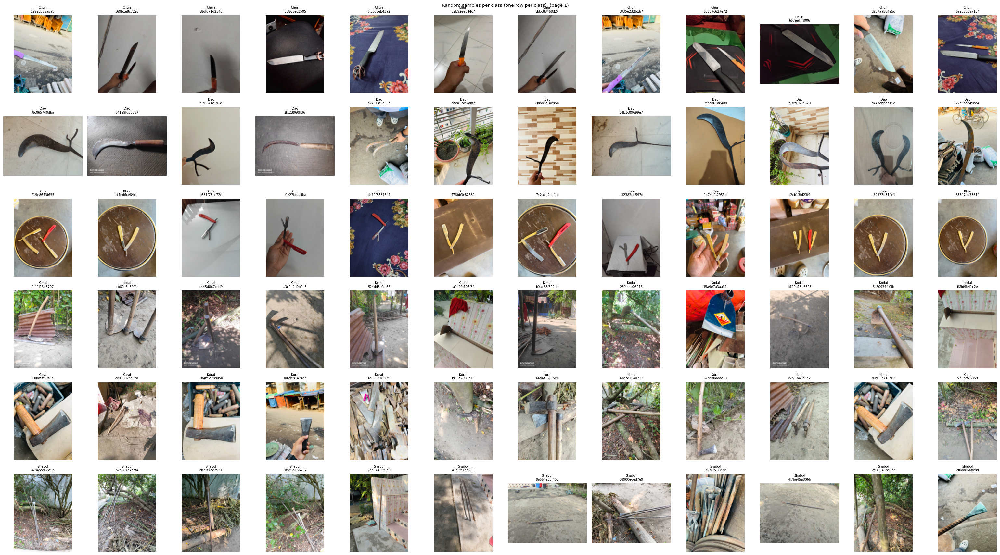

[PosixPath('/kaggle/working/stage0/figures/class_samples_p01.png')]

In [12]:
# Random samples per class: a quick visual label check
rng = np.random.default_rng(SEED)
sample_ids, sample_titles = [], []
for cls in CLASSES:
    ids = ok.image_id[ok.orig_label == cls].to_numpy()
    for iid in rng.choice(ids, size=min(12, len(ids)), replace=False):
        sample_ids.append(iid); sample_titles.append(f"{cls}\n{iid}")
contact_sheet(sample_ids, sample_titles, "class_samples", ncols=12, per_page=12 * len(CLASSES),
              thumb=160, suptitle="Random samples per class (one row per class)")

## 7. Apply review decisions and remove duplicates

Review decisions first (drop / relabel), then duplicate removal on what remains, using the updated labels. Within each same-label duplicate cluster one photo is kept: the one with the largest original resolution, ties broken by sharpness. With `KEEP_NAMED_COPIES`, a photo and its `_left/_up/_down` files count as one unit: they are kept or removed together, and are never removed as duplicates of each other.

In [13]:
dec = dict(zip(review.image_id, review.decision))
final = ok.copy()
final["label"] = final.orig_label
final["status_final"] = "kept"
for iid, d in dec.items():
    m = final.image_id == iid
    if d == "drop":
        final.loc[m, "status_final"] = "dropped_review"
    elif d.startswith("relabel:"):
        final.loc[m, "label"] = d.split(":", 1)[1]

import re
def unit_of(rel):
    stem = rel.rsplit(".", 1)[0]
    return re.sub(r"_(left|up|down)$", "", stem) if KEEP_NAMED_COPIES else stem
final["unit"] = final.rel_path.map(unit_of)

alive = (final.status_final == "kept").to_numpy()
idx_alive = np.flatnonzero(alive)
sub_near = near[np.ix_(idx_alive, idx_alive)]
a, b = np.nonzero(np.triu(sub_near, 1))
comp = connected_components(len(idx_alive), zip(a, b))
final["dup_cluster"] = -1
final.loc[idx_alive, "dup_cluster"] = comp
sizes = final.loc[idx_alive].groupby("dup_cluster").image_id.transform("size")
final.loc[idx_alive[sizes.to_numpy() == 1], "dup_cluster"] = -1

remove_units, n_clusters = set(), 0
for c, grp in final[final.dup_cluster >= 0].groupby("dup_cluster"):
    for _, g in grp.groupby("label"):
        units = g.unit.unique()
        if len(units) < 2:
            continue                      # only one photo (plus its named copies): nothing to remove
        n_clusters += 1
        best = g.assign(px=g.orig_w * g.orig_h).sort_values(["px", "lap_var"], ascending=False).unit.iloc[0]
        remove_units |= set(units) - {best}
if REMOVE_DUPLICATES:
    rm = final.unit.isin(remove_units) & (final.status_final == "kept")
    final.loc[rm, "status_final"] = "duplicate_removed"
    print(f"Duplicate clusters resolved: {n_clusters} | images removed as duplicates: {int(rm.sum())}")
else:
    print(f"Duplicate clusters found: {n_clusters} (REMOVE_DUPLICATES = False: all kept)")
final["dup_cluster_size"] = 1

inv_final = inv.merge(final[["image_id", "label", "status_final", "qc_flags"]], on="image_id", how="left")
inv_final["status_final"] = inv_final.status_final.fillna(inv_final.status)
inv_final.to_csv(META / "inventory.csv", index=False)

kept = final[final.status_final == "kept"].copy()
print(inv_final.status_final.value_counts().to_string())
relabelled = kept[kept.label != kept.orig_label]
if len(relabelled):
    print(f"\nRelabelled: {len(relabelled)}")
    display(relabelled[["image_id", "rel_path", "orig_label", "label"]])
print(f"\nFinal images: {len(kept)}")
display(pd.crosstab(kept.label, kept.subset, margins=True, margins_name="total").reindex(CLASSES + ["total"]))
counts = kept.label.value_counts()
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")

Duplicate clusters resolved: 61 | images removed as duplicates: 125
status_final
kept                 2950
duplicate_removed     125

Final images: 2950


subset,multi,single,total
label,,,
Churi,221,300,521
Dao,223,307,530
Khor,139,332,471
Kodal,187,290,477
Kural,179,298,477
Shabol,225,249,474
total,1174,1776,2950


Imbalance ratio (max/min): 1.13


## 8. Leakage-safe grouping

Images that are visually very similar (same object, same session, slight reframing) must never be split between train and test. Groups are built by linking images whose pHash distance (direct or mirrored) is within `GROUP_PHASH_THR`, plus any groups you supply in `GROUPS_CSV`.

A loose threshold on photos shot against the same background can chain many unrelated images into one giant group. If any group exceeds `MAX_GROUP_FRAC` of the data, the threshold is tightened automatically.

In [14]:
kidx = kept.index.to_numpy()            # positions in `ok` (and in the distance matrices)
nk = len(kidx)
pm_k = phash_min[np.ix_(kidx, kidx)]
near_k = near[np.ix_(kidx, kidx)]

user_edges = []
if GROUPS_CSV:
    ug = pd.read_csv(GROUPS_CSV, dtype=str)
    gmap = dict(zip(ug.rel_path, ug.group_id))
    gid = kept.rel_path.map(gmap)
    print(f"GROUPS_CSV rows matched to images: {gid.notna().sum()} of {len(ug)}")
    if gid.notna().sum() < 0.9 * len(ug):
        warnings.warn("Many GROUPS_CSV paths do not match the dataset. rel_path should look like 'Class/<file name>'.")
    for _, pos in pd.Series(np.arange(nk))[gid.notna().to_numpy()].groupby(gid.dropna().to_numpy()):
        user_edges += list(zip(pos.to_numpy()[:-1], pos.to_numpy()[1:]))
    print(f"User-defined group links: {len(user_edges)}")

# Files <name>_left / _up / _down (any extension) are tied to <name> in the same folder
import re
base_name = kept.rel_path.map(lambda r: re.sub(r"_(left|up|down)$", "", r.rsplit(".", 1)[0]))
for _, pos in pd.Series(np.arange(nk)).groupby(base_name.to_numpy()):
    if len(pos) > 1:
        user_edges += list(zip(pos.to_numpy()[:-1], pos.to_numpy()[1:]))

max_size = max(2, int(np.ceil(MAX_GROUP_FRAC * nk)))
for thr in range(GROUP_PHASH_THR, -1, -1):
    ga, gb = np.nonzero(np.triu((pm_k <= thr) | near_k, 1))
    groups = connected_components(nk, list(zip(ga, gb)) + user_edges)
    biggest = np.bincount(groups).max()
    if biggest <= max_size or thr == 0:
        break
    print(f"  threshold {thr}: largest group has {biggest} images (> {max_size}), tightening")
GROUP_THR_USED = thr
kept["group_id"] = groups
gsz = np.bincount(groups)
print(f"Group threshold used: {GROUP_THR_USED} | groups: {len(gsz)} | "
      f"multi-image groups: {(gsz > 1).sum()} | largest group: {gsz.max()} images")
if user_edges and biggest > max_size:
    warnings.warn("Largest group is still bigger than MAX_GROUP_FRAC (fine for small test sets; check GROUPS_CSV if one is used).")

  threshold 12: largest group has 93 images (> 59), tightening
  threshold 11: largest group has 69 images (> 59), tightening
  threshold 10: largest group has 69 images (> 59), tightening
Group threshold used: 9 | groups: 2501 | multi-image groups: 220 | largest group: 21 images


## 9. Splits: held-out test set + stratified group k-fold

Stratification uses **class x subset** (12 strata for 6 classes), so the single and multi parts are each balanced too.

1. `StratifiedGroupKFold` sets aside about `TEST_FRACTION` of the groups as the **test set**. It is used only once, for the final numbers.
2. The rest (`trainval`) is split into `N_FOLDS` stratified group folds. All pipeline and model selection uses these folds.

Both steps keep class proportions and never split a group.

label,Churi,Dao,Khor,Kodal,Kural,Shabol,total
split,,,,,,,
fold 0,89,85,89,80,88,76,507
fold 1,82,91,84,91,76,78,502
fold 2,91,90,96,81,87,80,525
fold 3,100,91,65,78,81,84,499
fold 4,91,94,75,80,82,76,498
test,68,79,62,67,63,80,419


Per split, class and subset:


label          Churi  Dao  Khor  Kodal  Kural  Shabol  total
split  subset                                               
fold 0 multi      40   37    12     31     29      35    184
       single     49   48    77     49     59      41    323
fold 1 multi      33   39    34     35     28      36    205
       single     49   52    50     56     48      42    297
fold 2 multi      36   39    44     33     29      42    223
       single     55   51    52     48     58      38    302
fold 3 multi      39   35    14     32     34      46    200
       single     61   56    51     46     47      38    299
fold 4 multi      42   37    23     29     32      35    198
       single     49   57    52     51     50      41    300
test   multi      31   36    12     27     27      31    164
       single     37   43    50     40     36      49    255

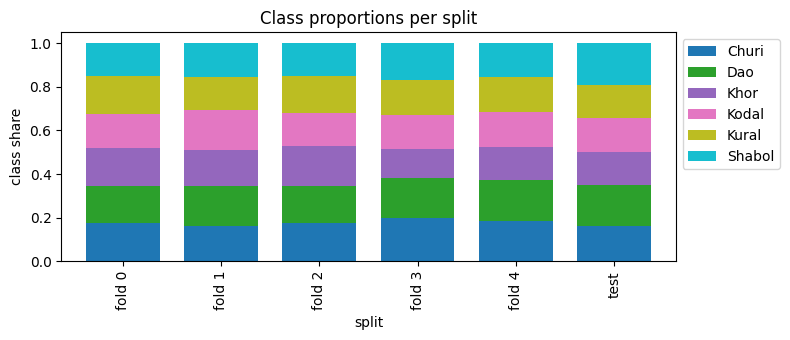

In [15]:
# stratify on class x subset, so single and multi are both balanced in the test set and in every fold
y = (kept.label.map({c: i for i, c in enumerate(CLASSES)}) * 2 + (kept.subset == "multi").astype(int)).to_numpy()
g = kept.group_id.to_numpy()
pos = np.arange(nk)

n_test_splits = max(2, round(1 / TEST_FRACTION))
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    _, test_pos = next(StratifiedGroupKFold(n_splits=n_test_splits, shuffle=True,
                                            random_state=SEED).split(pos, y, g))
kept["split"] = "trainval"
kept.iloc[test_pos, kept.columns.get_loc("split")] = "test"

kept["fold"] = -1
tv = np.flatnonzero(kept.split.to_numpy() == "trainval")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    for k, (_, val_pos) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True,
                                                          random_state=SEED).split(tv, y[tv], g[tv])):
        kept.iloc[tv[val_pos], kept.columns.get_loc("fold")] = k

# ---- leakage and coverage checks ----
test_groups = set(kept.group_id[kept.split == "test"])
assert not test_groups & set(kept.group_id[kept.split == "trainval"]), "Group leakage between test and trainval"
assert (kept[kept.split == "trainval"].groupby("group_id").fold.nunique() == 1).all(), "Group split across folds"
assert (kept.loc[kept.split == "trainval", "fold"] >= 0).all()
assert not (set(kept.pixel_md5[kept.split == "test"]) & set(kept.pixel_md5[kept.split == "trainval"]))

tab = pd.crosstab(kept.split.where(kept.split == "test", "fold " + kept.fold.astype(str)),
                  kept.label).reindex(columns=CLASSES, fill_value=0)
tab["total"] = tab.sum(axis=1)
display(tab)
if (tab[CLASSES] == 0).any().any():
    warnings.warn("At least one class is missing from the test set or a fold. "
                  "Collect more images for that class or reduce N_FOLDS / TEST_FRACTION.")

where = kept.split.where(kept.split == "test", "fold " + kept.fold.astype(str))
sub_tab = pd.crosstab([where.rename("split"), kept.subset], kept.label).reindex(columns=CLASSES, fill_value=0)
sub_tab["total"] = sub_tab.sum(axis=1)
print("Per split, class and subset:")
display(sub_tab)
sub_tab.to_csv(META / "split_class_subset_counts.csv")
if (sub_tab[CLASSES] == 0).any().any():
    warnings.warn("Some class has no single or no multi images in the test set or a fold. "
                  "The Single or Multi scenario may then miss that class there.")

prop = tab[CLASSES].div(tab[CLASSES].sum(axis=1), axis=0)
ax = prop.plot(kind="bar", stacked=True, figsize=(8, 3.5), colormap="tab10", width=0.75)
ax.set_ylabel("class share"); ax.set_title("Class proportions per split"); ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(FIG / "split_class_balance.png", dpi=120); plt.show()

## 10. Save manifest and report

In [16]:
class_map = {c: i for i, c in enumerate(CLASSES)}
manifest = kept.assign(
    path=kept.image_id.map(lambda i: std_path(i).relative_to(OUT_ROOT).as_posix()),
    label_idx=kept.label.map(class_map),
)[["image_id", "path", "label", "label_idx", "subset", "part", "orig_label", "split", "fold", "group_id",
   "rel_path", "width", "height", "orig_w", "orig_h", "upscale_candidate",
   "lap_var", "mean_lum", "std_lum", "mean_sat", "qc_flags"]].sort_values(["split", "fold", "label", "image_id"])
manifest.to_csv(META / "manifest.csv", index=False)
(META / "class_map.json").write_text(json.dumps(class_map, indent=2))

cfg_keys = ["SEED", "MAX_SIDE", "DUP_PHASH_THR", "DUP_DHASH_THR", "CHECK_MIRRORED", "DUP_VERIFY_GRAY_CORR", "DUP_VERIFY_EDGE_CORR", "QUALITY_SIDE",
            "BLUR_MAD_K", "MIN_SHORT_SIDE", "UPSCALE_CANDIDATE_SIDE", "DARK_MEAN", "BRIGHT_MEAN",
            "CLIP_FRAC", "LOW_CONTRAST_STD", "USE_EMBEDDINGS", "KNN_K", "KNN_DISAGREE_FRAC",
            "OUTLIER_MAD_K", "TEST_FRACTION", "N_FOLDS", "GROUP_PHASH_THR", "MAX_GROUP_FRAC", "GROUPS_CSV"]
report = {
    "data_root": str(DATA_ROOT), "parts": [str(p) for p in PART_ROOTS], "classes": CLASSES,
    "config": {k: (str(globals()[k]) if isinstance(globals()[k], Path) else globals()[k]) for k in cfg_keys},
    "derived": {"blur_threshold_log10_lapvar": round(float(BLUR_THR), 4),
                "group_phash_threshold_used": int(GROUP_THR_USED),
                "embedding_audit_ran": E is not None},
    "counts": {"raw_files": int(len(inv)),
               **{k: int(v) for k, v in inv_final.status_final.value_counts().items()},
               "final_per_class": {c: int((kept.label == c).sum()) for c in CLASSES},
               "final_per_class_subset": {c: {s_: int(((kept.label == c) & (kept.subset == s_)).sum())
                                              for s_ in ["single", "multi"]} for c in CLASSES},
               "test_per_subset": {s_: int(((kept.split == "test") & (kept.subset == s_)).sum()) for s_ in ["single", "multi"]},
               "test": int((kept.split == "test").sum()),
               "per_fold_val": {int(k): int(v) for k, v in kept[kept.split == "trainval"].fold.value_counts().sort_index().items()},
               "relabelled": int((kept.label != kept.orig_label).sum()),
               "duplicates_removed": int((inv_final.status_final == "duplicate_removed").sum()),
               "groups": int(kept.group_id.nunique())},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "opencv": cv2.__version__, "pillow": PIL_VERSION, "imagehash": imagehash.__version__,
                 "scikit-learn": sklearn.__version__},
}
(META / "stage0_report.json").write_text(json.dumps(report, indent=2))

print(f"Manifest: {META / 'manifest.csv'}  ({len(manifest)} images)")
print(json.dumps(report["counts"], indent=2))

Manifest: /kaggle/working/stage0/metadata/manifest.csv  (2950 images)
{
  "raw_files": 3075,
  "kept": 2950,
  "duplicate_removed": 125,
  "final_per_class": {
    "Churi": 521,
    "Dao": 530,
    "Khor": 471,
    "Kodal": 477,
    "Kural": 477,
    "Shabol": 474
  },
  "final_per_class_subset": {
    "Churi": {
      "single": 300,
      "multi": 221
    },
    "Dao": {
      "single": 307,
      "multi": 223
    },
    "Khor": {
      "single": 332,
      "multi": 139
    },
    "Kodal": {
      "single": 290,
      "multi": 187
    },
    "Kural": {
      "single": 298,
      "multi": 179
    },
    "Shabol": {
      "single": 249,
      "multi": 225
    }
  },
  "test_per_subset": {
    "single": 255,
    "multi": 164
  },
  "test": 419,
  "per_fold_val": {
    "0": 507,
    "1": 502,
    "2": 525,
    "3": 499,
    "4": 498
  },
  "relabelled": 0,
  "duplicates_removed": 125,
  "groups": 2501
}


## How later notebooks use this

Notebooks 1 to 3 load the manifest and uses the same folds and test set. Images are read from `OUT_ROOT / path`.

```python
import pandas as pd
from pathlib import Path

# Kaggle: Add Input -> Your Work -> this Stage 0 notebook
OUT_ROOT = Path("/kaggle/input/<stage0-notebook-name>/stage0")   # locally: Path(r"H:\BD Weapon Stage0")
m = pd.read_csv(OUT_ROOT / "metadata/manifest.csv")

test = m[m.split == "test"]                      # touch only for the final report
for k in range(5):     # N_FOLDS
    train = m[(m.split == "trainval") & (m.fold != k)]
    val   = m[(m.split == "trainval") & (m.fold == k)]
    # ... run pipeline Px on train/val with the shared training script
```

Notes for the methods section: report the counts in `stage0_report.json` (raw files, unreadable, duplicate clusters and copies (all kept), dropped or relabelled in review, final per class), the duplicate thresholds, the group threshold used, and that splits are grouped by visual similarity to prevent near-duplicate leakage.